# Analysis Report of State Capitals
### Hannah Jamison
### November 15, 2026

I chose to go with the State Capitals data set as I thought I had come up with a bit of an interesting hyopthesis based on the data it gives you. In this JSON file I have access to the state, state capital, population, year founded, latitude, and longitude. The two parts I will be focusing on is the population of the state capital and its latitude. 

Link to dataset: https://jsonlint.com/datasets/us-capitals

The question I have is, does the capitals latitude have an impact on its population? My hyopthesis is that the capitals with the lower latitude will have a higher population. This is because the United States is completely above the equator, so the lower the latitude, the closer you are to a warmer climate. I believe a capital in a warmer climate would draw more people in over one that is colder.

## Part 1

In [61]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.formula.api import ols

df = pd.read_json("us-capitals.json")
display(df.head())
print(df.columns)

,capitals
0,"{'state': 'Alabama', 'capital': 'Montgomery', ..."
1,"{'state': 'Alaska', 'capital': 'Juneau', 'popu..."
2,"{'state': 'Arizona', 'capital': 'Phoenix', 'po..."
3,"{'state': 'Arkansas', 'capital': 'Little Rock'..."
4,"{'state': 'California', 'capital': 'Sacramento..."


Index(['capitals'], dtype='str')


In [62]:
df = pd.DataFrame(df.iloc[:, 0].tolist())
df.columns = ['State', 'Capital', 'Population', 'Founded', 'Lat', 'Lon']

df

,State,Capital,Population,Founded,Lat,Lon
0,Alabama,Montgomery,198525,1819,32.377716,-86.300568
1,Alaska,Juneau,32255,1906,58.301935,-134.419740
2,Arizona,Phoenix,1608139,1912,33.448457,-112.073844
3,Arkansas,Little Rock,197312,1821,34.736009,-92.331122
4,California,Sacramento,508529,1854,38.555605,-121.468926
5,Colorado,Denver,715522,1867,39.739236,-104.990251
6,Connecticut,Hartford,122587,1875,41.763711,-72.685093
7,Delaware,Dover,38470,1777,39.161921,-75.526755
8,Florida,Tallahassee,194500,1824,30.438256,-84.280733
9,Georgia,Atlanta,498715,1868,33.749027,-84.388229


After displaying the first data frame, I knew I needed to split the data up into seperate columns so everything was easily visible. I tried to research for a while on how to do it properly, but nothing was quite working. I then used ChatGPT and it gave me the code line "(df.iloc[:, 0].tolist())" which fixed the problems I was having (the code only had one column when I wanted six and the data was under a few layers).

## Part 2

### Histogram

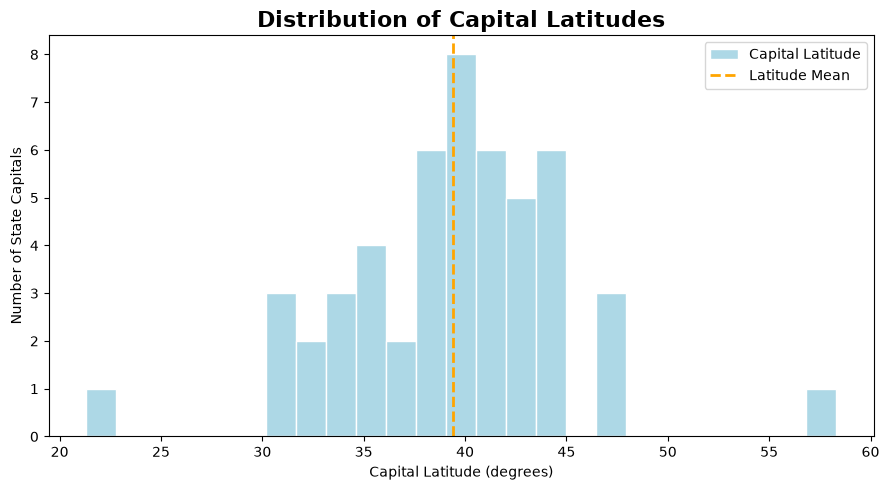

In [63]:
fig, ax = plt.subplots(figsize=(9,5))


ax.hist(df["Lat"], 
        bins=25,
        color="lightblue",
        edgecolor="white",
        label="Capital Latitude"
)

mean_latitude = df["Lat"].mean()


ax.axvline(
    mean_latitude,
    color="orange",
    linestyle="--",
    linewidth=2,
    label="Latitude Mean"
)

plt.title(
    "Distribution of Capital Latitudes",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Capital Latitude (degrees)")
plt.ylabel("Number of State Capitals")
plt.legend()
plt.tight_layout()
plt.show()

The distribution of the state capital's latitude is a little varied, but most ranges from 30 to 45 degrees. There is two outliers within this dataset, which does make sense, as they are Hawaii and Alaska, both of which are not directly next to the rest of the states. I did try a handful of different bin sizes and landed on 25. When it was lower, I felt that the data was to clumped together for it being all numbers that are relativley close together, but I also didn't want the chart to be too big and be too much data to take in. 

### Scatter Plot

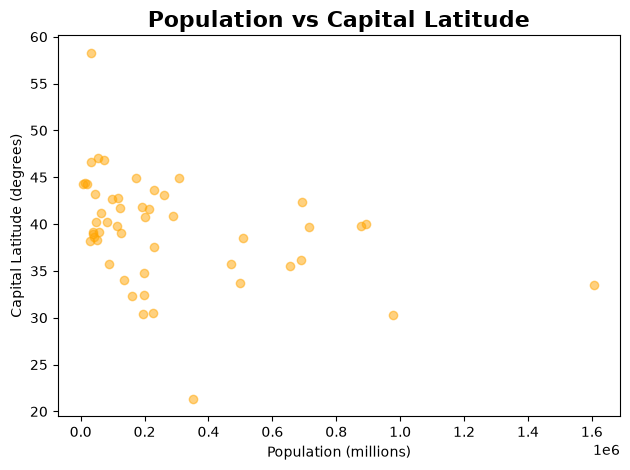

In [64]:
plt.scatter(
    df["Population"],
    df["Lat"],
    color="orange",
    alpha=0.5
)

plt.title(
    "Population vs Capital Latitude",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("Population (millions)")
plt.ylabel("Capital Latitude (degrees)")
plt.tight_layout()
plt.show()

From this graph it is apparent that a lot of the states have a similar latitude also have a similar population level. I believe that between the three charts, this one helps answer the question I posed at the beginning the most. You are able to easily check the population levels of the capitals with the highest and lowest latitude.

### Box Plot

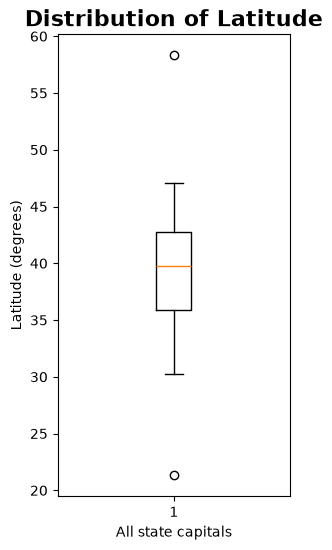

In [65]:
with plt.style.context("ggplot"):
    plt.figure(figsize=(3,6))

plt.boxplot(df["Lat"])
plt.title(
    "Distribution of Latitude",
    fontsize=16,
    fontweight="bold"
)
plt.xlabel("All state capitals")
plt.ylabel("Latitude (degrees)")
plt.show()

With the box plot you can only really see the distrubution of one set of data, so it doesn't really help much with my hypothesis. Though it does show the best between the three graphs how many states have a similar latitude and the two major outliers.

## Part 3

Between the three charts I decided on a color scheme of light blue and orange so they all looked cohesive. I also bolded and made the titles of each chart larger so they stood out against the rest of the text. I made the most visual changes to the histogram chart so the data was more visible for the audience. That chart is the only one with a legend as the I added the extra line to represent the mean of the latitudes. The other three charts did not need a legend as it would just be redudant of the x and y axis lables. On the scatter plot I did lower the alpha so the overlapping dots where more visible since there was so many. Lastly, with the box plot I changed the size of the chart so there was less open space and audience would be able to connect the tick markers better to the box and whiskers.

## Part 4

In [69]:
correlation = df["Lat"].corr(
    df["Population"]
)
print("Correlation: ", correlation)

Correlation:  -0.3442872805212421


In [70]:
model_b = ols(
    "Lat ~ Population",
    data=df
).fit()

print(model_b.summary())

                            OLS Regression Results                            
Dep. Variable:                    Lat   R-squared:                       0.119
Model:                            OLS   Adj. R-squared:                  0.100
Method:                 Least Squares   F-statistic:                     6.455
Date:                Mon, 16 Nov 2026   Prob (F-statistic):             0.0144
Time:                        16:30:00   Log-Likelihood:                -154.55
No. Observations:                  50   AIC:                             313.1
Df Residuals:                      48   BIC:                             316.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     41.0813      1.011     40.639      0.0

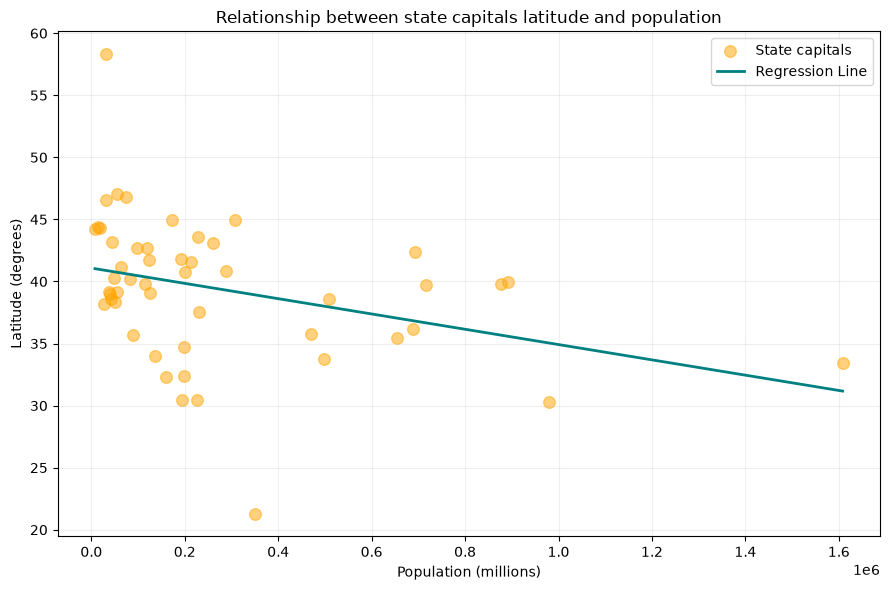

In [75]:
df_sorted = df.sort_values("Population")

predicted = model_b.predict(df_sorted)
plt.figure(figsize=(9,6))

plt.scatter(
    df["Population"],
    df["Lat"],
    color="orange",
    alpha=0.5,
    s=70,
    label="State capitals"
)

plt.plot(
    df_sorted["Population"],
    predicted,
    color="teal",
    linewidth=2,
    label="Regression Line"
)

plt.xlabel("Population (millions)")
plt.ylabel("Latitude (degrees)")
plt.title("Relationship between state capitals latitude and population")
plt.legend()
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

I went with option b due to there not being two groups to compare data between, which you need for option a. Option b also showed the correlation between the latitude and the population, which is exactly what I was looking for with my question I came up with at the beginning of this analysis. When I first saw the correlation number it was negative, so I assumed that my hypothesis was incorrect. Though once I put in the graph with the regression line, its slope is going down, meaning as the latitude of the state capital is lower, the higher population it has.

## Part 5

In the end, this data proves my orginal hypothesis correct, state capitals with a lower latitude have higher populations. The graph from the statistical analysis I believe to be the best way to visually see the results. Before I did this section, I had already thought the scatter plot was the best way to visually see the data, yet it still wasn't the easiest to read. You constantly had to look back and forth between the points and see where each one was on the x and y axis. With the statistical analysis graph the line of regression easily shows that the lower the latitude is, the higher the population is. Before I did the statistical analysis I was assuming that my hypothesis was incorrect due to the larger grouping of capitals at a similar latitude. I was looking at each point individually, but when the line was added in, it became more apparent that population was getting larger with the lower latitude capitals. A major limitation with this data is that this is for only the capitals of each state, not the whole state. It is not capturing the whole population, if it did have the whole state's population that would change the data results. For example, Florida's the state capital is Tallahassee which is in the panhandle, there is a ton of people who are in the more southern section of Florida. Though if you did the whole state, it would be difficult to choose what section for the latitude. I believe the best option overall would be to just pick the most populated city in the state instead of the capital.